<a href="https://colab.research.google.com/github/adityakumarsinghcs24-ship-it/BIO_INSPIRED/blob/main/Week_6_ParallelCellularOptimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

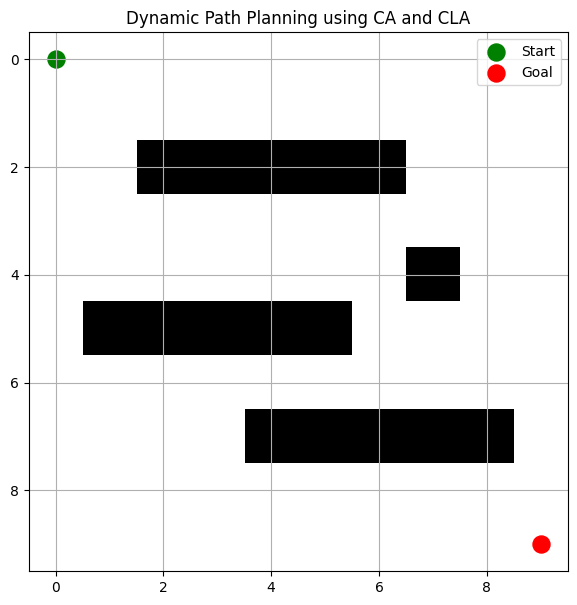

No valid path found


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import random

# Grid environment: 0 = free, 1 = obstacle
grid = np.zeros((10, 10))

# Add obstacles
grid[2, 2:7] = 1
grid[5, 1:6] = 1
grid[7, 4:9] = 1

start = (0, 0)
goal = (9, 9)

# Possible movements
moves = [(-1,0), (1,0), (0,-1), (0,1)]

# Learning rate
alpha = 0.2

# Initialize learning probabilities
Q = np.ones((10, 10, 4)) / 4

def valid(pos):
    x, y = pos
    return (0 <= x < 10 and 0 <= y < 10
            and grid[x, y] == 0)

def find_path():
    pos = start
    path = [pos]
    visited = {pos}

    for step in range(100):
        if pos == goal:
            return path

        x, y = pos

        choices = []
        for i, (dx, dy) in enumerate(moves):
            nxt = (x + dx, y + dy)
            if valid(nxt) and nxt not in visited:
                choices.append(i)

        if not choices:
            return None

        # Select action using learned probabilities
        probabilities = Q[x, y, choices]
        probabilities = probabilities / probabilities.sum()

        action = np.random.choice(choices, p=probabilities)

        dx, dy = moves[action]
        new_pos = (x + dx, y + dy)

        # Reward progress toward destination
        old_dist = abs(x-goal[0]) + abs(y-goal[1])
        new_dist = abs(new_pos[0]-goal[0]) + abs(new_pos[1]-goal[1])

        reward = 1 if new_dist < old_dist else 0

        if reward:
            Q[x, y, action] += alpha * (
                1 - Q[x, y, action]
            )
        else:
            Q[x, y, action] *= (1-alpha)

        Q[x, y] /= Q[x, y].sum()

        pos = new_pos
        path.append(pos)
        visited.add(pos)

    return None

# Initial path planning
path = find_path()

# Introduce a dynamic obstacle
grid[4, 7] = 1

# Recalculate path
new_path = find_path()

# Display result
plt.figure(figsize=(7, 7))
plt.imshow(grid, cmap='gray_r')

if new_path:
    px, py = zip(*new_path)
    plt.plot(py, px, 'b-o', label='Optimized Path')

plt.scatter(start[1], start[0], c='green',
            s=150, label='Start')
plt.scatter(goal[1], goal[0], c='red',
            s=150, label='Goal')

plt.title("Dynamic Path Planning using CA and CLA")
plt.legend()
plt.grid()
plt.show()

if new_path:
    print("Optimal path:", new_path)
    print("Path length:", len(new_path)-1)
else:
    print("No valid path found")